# E2 : YOLOv8s à 640 × 640 (suite de E0 et E1)

**Objectif :** entraîner YOLOv8s dans *exactement* les mêmes conditions que E0 (YOLOv8n, 640 px), puis comparer E0, E1 et E2.

| Expérience | Modèle | Résolution | État |
|---|---|---|---|
| E0 | YOLOv8n | 640 | déjà fait (Drive : `runs/e0_640`) |
| E1 | YOLOv8n | 960 | déjà fait (Drive : `runs/e1_960-2`) |
| **E2** | **YOLOv8s** | **640** | **ce notebook** |

Seul paramètre qui change entre E0 et E2 : le modèle (`yolov8n.pt` → `yolov8s.pt`).

**Important :** Colab efface `/content` à chaque nouvelle session. Seul Drive est conservé.
Si la session est réinitialisée, il faut ré-exécuter les cellules 1 à 3 avant de continuer.

**Activer le GPU avant de commencer :** Exécution → Modifier le type d'exécution → GPU T4.

## 1. Installation, Drive et GPU

In [ ]:
print("hello")

hello


In [ ]:
!pip install -q ultralytics

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import torch
print("GPU disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("ATTENTION : pas de GPU. Active-le avant de lancer l'entraînement.")

GPU disponible : True
GPU : Tesla T4


## 2. Données

- **Validation (548 images)** : `check_det_dataset("VisDrone.yaml")` télécharge VisDrone et convertit les annotations au format YOLO automatiquement. C'est ce qui a servi pour E0 et E1.
- **Entraînement (2 000 images)** : on décompresse `visdrone_sub.zip` depuis Drive (même sous-ensemble que E0 et E1).

In [ ]:
from ultralytics.data.utils import check_det_dataset
from pathlib import Path

# Validation : téléchargement + conversion automatique (quelques minutes)
check_det_dataset("VisDrone.yaml")

# Entraînement : les 2000 images de E0/E1
!unzip -q -o /content/drive/MyDrive/visdrone_sub.zip -d /content

# Vérification
val_img = len(list(Path("/content/datasets/VisDrone/images/val").glob("*.jpg")))
val_lbl = len(list(Path("/content/datasets/VisDrone/labels/val").glob("*.txt")))
tr_img  = len(list(Path("/content/visdrone_sub/images").glob("*.jpg")))
tr_lbl  = len(list(Path("/content/visdrone_sub/labels").glob("*.txt")))

print("Validation :", val_img, "images /", val_lbl, "labels   (attendu : 548 / 548)")
print("Entraînement :", tr_img, "images /", tr_lbl, "labels   (attendu : 2000 / 2000)")
assert val_img == 548 and val_lbl == 548, "Problème avec la validation"
assert tr_img == 2000 and tr_lbl == 2000, "Problème avec l'entraînement"
print("Données OK.")

Validation : 548 images / 548 labels   (attendu : 548 / 548)
Entraînement : 2000 images / 2000 labels   (attendu : 2000 / 2000)
Données OK.


## 3. Fichier `data.yaml` (identique à celui de E0 et E1)

In [ ]:
yaml_text = """
path: /content/datasets/VisDrone
train: /content/visdrone_sub/images
val: images/val
test: images/test
names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor
"""
open("/content/data.yaml", "w").write(yaml_text)
print(open("/content/data.yaml").read())


path: /content/datasets/VisDrone
train: /content/visdrone_sub/images
val: images/val
test: images/test
names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor



## 4. Entraînement E2 : YOLOv8s, 640 px

Paramètres identiques à E0 : 30 époques, batch 16, seed 0, workers 2.
Durée estimée : environ 40 à 60 minutes sur un T4 (E0 en YOLOv8n avait pris environ 24 min). **Garde l'onglet Colab ouvert.**

Les résultats sont enregistrés directement sur Drive (`runs/e2_s640`).

In [12]:
from ultralytics import YOLO

m = YOLO("yolov8s.pt")
m.train(
    data="/content/data.yaml",
    imgsz=640,
    epochs=30,
    batch=16,
    seed=0,
    workers=2,
    project="/content/drive/MyDrive/runs",
    name="e2_s640",
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=e2_s640, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ce269199780>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

### 4 bis. Si la session s'est coupée pendant l'entraînement

1. Ré-exécute les cellules 1, 2 et 3.
2. Exécute **uniquement** la cellule ci-dessous (elle reprend à la dernière époque sauvegardée), **à la place** de la cellule 4.

In [ ]:
# À utiliser seulement après une coupure
from ultralytics import YOLO
m = YOLO("/content/drive/MyDrive/runs/e2_s640/weights/last.pt")
m.train(resume=True)

## 5. Évaluation des trois modèles dans les mêmes conditions

On évalue E0, E1 et E2 **dans ce même notebook**, sur les mêmes 548 images, avec les mêmes réglages (`max_det=317`, car certaines images contiennent jusqu'à 317 objets) et sur le même GPU. Les temps d'inférence sont donc comparables.

- Résolution d'évaluation = résolution d'entraînement (640 pour E0 et E2, 960 pour E1).

In [13]:
from ultralytics import YOLO
import pandas as pd

BASE = "/content/drive/MyDrive"
experiences = {
    "E0 - v8n - 640": (f"{BASE}/runs/e0_640/weights/best.pt",   640, "e0_640_val_gpu"),
    "E1 - v8n - 960": (f"{BASE}/runs/e1_960-2/weights/best.pt", 960, "e1_960_val_gpu"),
    "E2 - v8s - 640": (f"{BASE}/runs/e2_s640/weights/best.pt",  640, "e2_s640_val"),
}

resultats = {}   # on garde les objets complets pour les graphiques par classe
lignes = []

for nom, (poids, imgsz, dossier) in experiences.items():
    print("\n=====", nom, "=====")
    model = YOLO(poids)
    r = model.val(
        data="/content/data.yaml",
        imgsz=imgsz,
        batch=16,
        max_det=317,
        project=f"{BASE}/evaluations",
        name=dossier,
        exist_ok=True,
        plots=True,
        verbose=False,
    )
    resultats[nom] = (model, r)
    lignes.append({
        "Expérience": nom,
        "Paramètres (M)": round(sum(p.numel() for p in model.model.parameters()) / 1e6, 2),
        "Précision": round(float(r.box.mp), 3),
        "Rappel": round(float(r.box.mr), 3),
        "mAP50": round(float(r.box.map50), 3),
        "mAP50-95": round(float(r.box.map), 3),
        "Inférence (ms/img)": round(float(r.speed["inference"]), 1),
    })

tableau = pd.DataFrame(lignes)
tableau.to_csv(f"{BASE}/evaluations/tableau_comparatif_E0_E1_E2.csv", index=False)
tableau


===== E0 - v8n - 640 =====
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3207.3±844.5 MB/s, size: 163.8 KB)
val: Scanning /content/datasets/VisDrone/labels/val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 153.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 2.3it/s 15.4s
                   all        548      38759      0.367      0.285      0.245      0.134
Speed: 1.5ms preprocess, 3.5ms inference, 0.0ms loss, 5.7ms postprocess per image
Results saved to /content/drive/MyDrive/evaluations/e0_640_val_gpu

===== E1 - v8n - 960 =====
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅

,Expérience,Paramètres (M),Précision,Rappel,mAP50,mAP50-95,Inférence (ms/img)
0,E0 - v8n - 640,3.14,0.367,0.285,0.245,0.134,3.5
1,E1 - v8n - 960,3.14,0.458,0.363,0.345,0.199,5.4
2,E2 - v8s - 640,11.14,0.449,0.337,0.318,0.179,4.8


## 6. Graphique 1 : indicateurs globaux

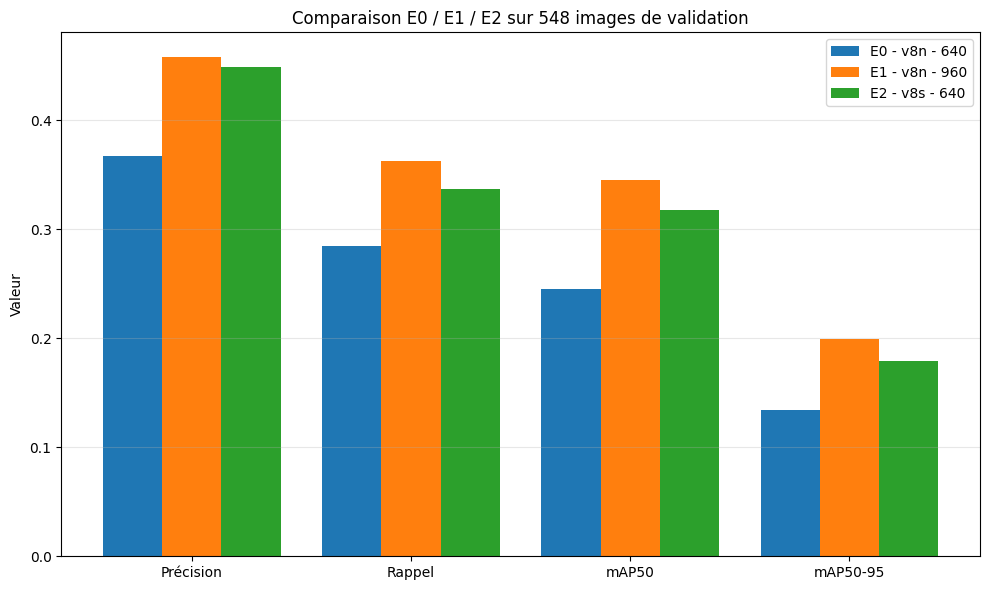

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

sortie = Path(f"{BASE}/evaluations/comparaison_E2")
sortie.mkdir(parents=True, exist_ok=True)

metriques = ["Précision", "Rappel", "mAP50", "mAP50-95"]
x = np.arange(len(metriques))
largeur = 0.27

plt.figure(figsize=(10, 6))
for i, (_, ligne) in enumerate(tableau.iterrows()):
    plt.bar(x + (i - 1) * largeur, [ligne[m] for m in metriques], largeur, label=ligne["Expérience"])

plt.xticks(x, metriques)
plt.ylabel("Valeur")
plt.title("Comparaison E0 / E1 / E2 sur 548 images de validation")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(sortie / "indicateurs_globaux.png", dpi=300)
plt.show()

## 7. Graphique 2 : mAP50 par classe

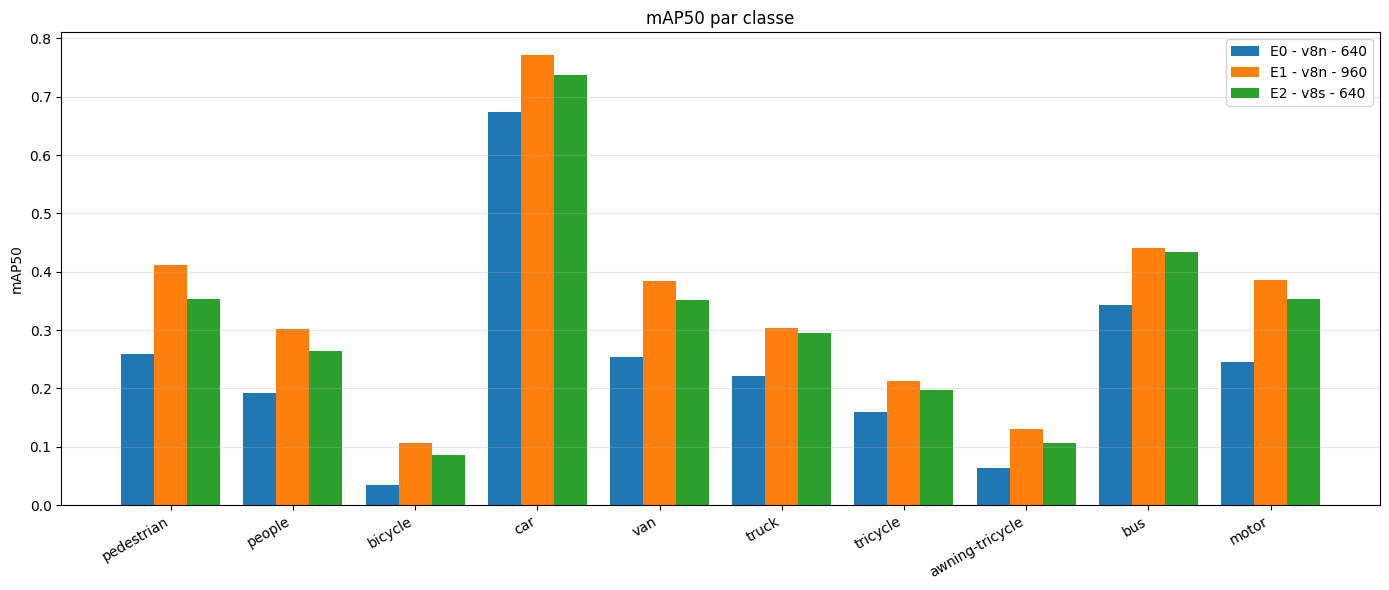

,E0 - v8n - 640,E1 - v8n - 960,E2 - v8s - 640
pedestrian,0.260,0.411,0.354
people,0.193,0.301,0.264
bicycle,0.035,0.106,0.085
car,0.674,0.772,0.737
van,0.255,0.384,0.351
truck,0.221,0.303,0.294
tricycle,0.159,0.212,0.197
awning-tricycle,0.063,0.131,0.107
bus,0.343,0.441,0.434
motor,0.246,0.385,0.354


In [15]:
noms_classes = ["pedestrian", "people", "bicycle", "car", "van",
                "truck", "tricycle", "awning-tricycle", "bus", "motor"]

ap_par_classe = {}
for nom, (model, r) in resultats.items():
    valeurs = np.zeros(len(noms_classes))
    valeurs[r.box.ap_class_index] = r.box.ap50      # ap50 : une valeur par classe présente
    ap_par_classe[nom] = valeurs

x = np.arange(len(noms_classes))
plt.figure(figsize=(14, 6))
for i, (nom, valeurs) in enumerate(ap_par_classe.items()):
    plt.bar(x + (i - 1) * largeur, valeurs, largeur, label=nom)

plt.xticks(x, noms_classes, rotation=30, ha="right")
plt.ylabel("mAP50")
plt.title("mAP50 par classe")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(sortie / "map50_par_classe.png", dpi=300)
plt.show()

pd.DataFrame(ap_par_classe, index=noms_classes).round(3)

## 8. Graphique 3 : compromis précision / vitesse

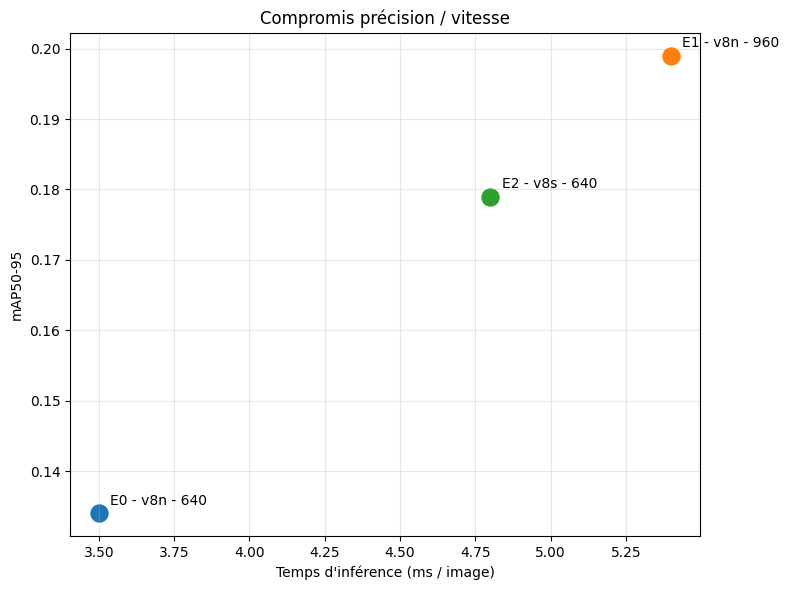

In [16]:
plt.figure(figsize=(8, 6))
for _, ligne in tableau.iterrows():
    plt.scatter(ligne["Inférence (ms/img)"], ligne["mAP50-95"], s=150)
    plt.annotate(ligne["Expérience"], (ligne["Inférence (ms/img)"], ligne["mAP50-95"]),
                 textcoords="offset points", xytext=(8, 6))

plt.xlabel("Temps d'inférence (ms / image)")
plt.ylabel("mAP50-95")
plt.title("Compromis précision / vitesse")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(sortie / "compromis_precision_vitesse.png", dpi=300)
plt.show()

## 9. Temps d'entraînement (depuis les `results.csv`)

In [17]:
temps = []
for nom, dossier in [("E0 - v8n - 640", "e0_640"), ("E1 - v8n - 960", "e1_960-2"), ("E2 - v8s - 640", "e2_s640")]:
    df = pd.read_csv(f"{BASE}/runs/{dossier}/results.csv")
    df.columns = df.columns.str.strip()
    temps.append({"Expérience": nom,
                  "Époques": len(df),
                  "Temps d'entraînement (min)": round(float(df['time'].iloc[-1]) / 60, 1)})
pd.DataFrame(temps)

,Expérience,Époques,Temps d'entraînement (min)
0,E0 - v8n - 640,30,24.0
1,E1 - v8n - 960,30,38.8
2,E2 - v8s - 640,30,26.8


## 10. Comment lire les résultats

- **E2 contre E0** : même résolution (640), seule la taille du modèle change. Si le mAP augmente, le gain vient du passage de n à s.
- **E2 contre E1** : un modèle plus gros contre une résolution plus haute. Cela montre ce qui rapporte le plus, plus de paramètres ou plus de pixels. Dans VisDrone, la majorité des objets sont petits, donc la résolution peut peser lourd.
- **Vitesse** : regarde la colonne « Inférence (ms/img) » et le temps d'entraînement. Un modèle un peu meilleur mais beaucoup plus lent n'est pas forcément le meilleur choix.
- **Prudence** : un seul entraînement (seed 0) sur 2 000 images. Une différence de quelques millièmes de mAP n'est pas significative, il faut le dire dans le rapport.

Fichiers produits sur Drive : `runs/e2_s640/`, `evaluations/e2_s640_val/`, `evaluations/comparaison_E2/` et le tableau CSV.